Эпизод 1

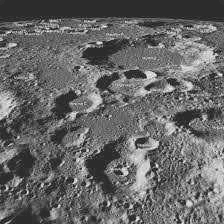

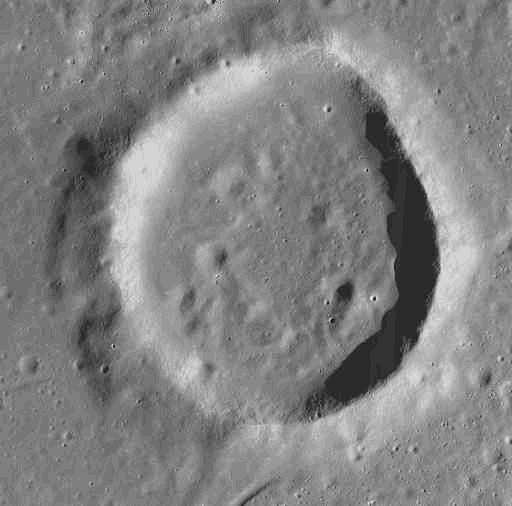

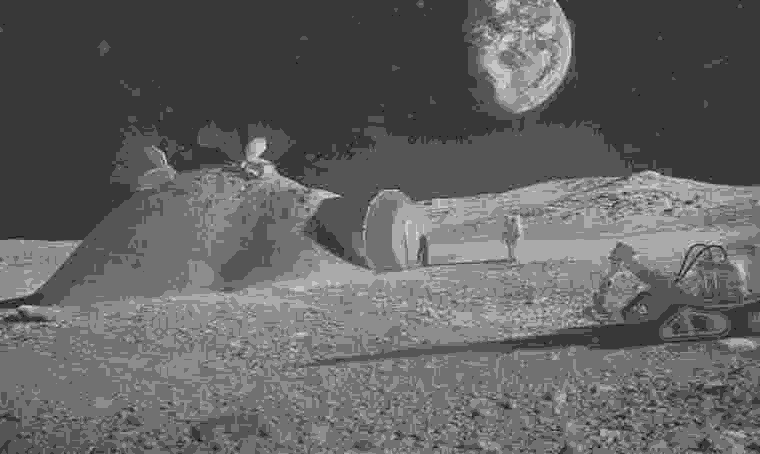

In [21]:
from PIL import Image
import numpy as np

paths = input().split()

for file_path in paths:
    img = Image.open(file_path)
    data = np.array(img)
    max_num = np.max(data)
    min_num = np.min(data)
    updated_data = (data-min_num)/(max_num-min_num)*255
    updated_data = np.clip(updated_data).astype(np.uint8)
    res_img = Image.fromarray(updated_data)
    display(res_img)


Эпизод 2

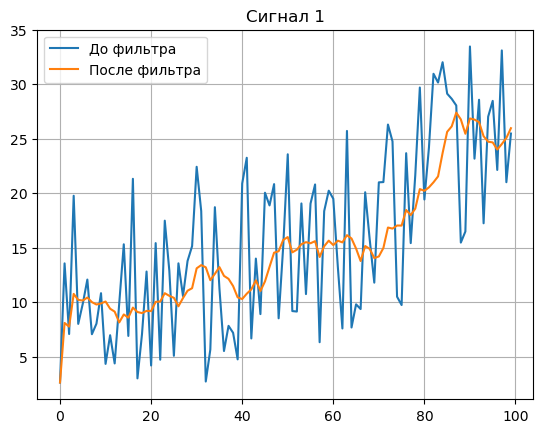

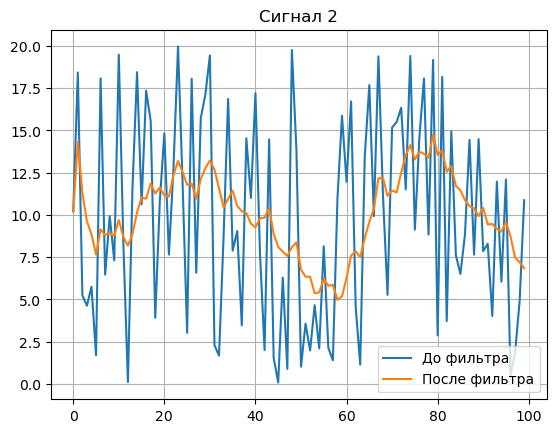

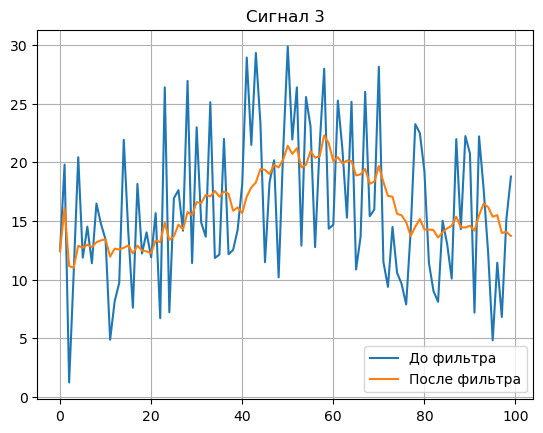

In [35]:
import matplotlib.pyplot as plt
import numpy as np

paths = input().split()
j=1
for path in paths:
    f = open(path, 'r')
    data = list(map(float, f.read().split()))
    t = np.array([i for i in range(len(data))])
    fig = plt.figure()
    ymin = np.min(data)
    ymax = np.max(data)
    plt.plot(t, data, label='До фильтра')
    plt.title('Сигнал %d' % j)
    plt.grid()
    filtered_data = []
    for i in range(len(data)):
        if i>=0 and i<=9:
            filtered_data.append(np.mean(data[0:i+1]))
        else:
            filtered_data.append(np.mean(data[i-9:i+1]))
    plt.plot(t, filtered_data, label='После фильтра')
    plt.legend()

    j+=1

Эпизод 3

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import imageio.v2 as imageio

path = input()
with open(path, 'r') as f:
    u0 = np.array(f.read().split(), dtype=float)
    N = len(u0)

    A = np.zeros((N, N))
    for i in range(N):
        A[i, i] = 1.0
        A[i, (i - 1) % N] = -1.0

    history = np.zeros((256, N))
    history[0] = u0
    u = u0.copy()

    for n in range(1, 256):
        u = u - 0.5 * (A @ u)
        history[n] = u

    images = []
    for n in range(256):
        fig = plt.figure(figsize=(8, 5))  # Каждый раз новый график
        plt.plot(np.arange(N), history[n])
        plt.title(f'Шаг n = {n}')
        plt.ylim(np.min(history) - 1, np.max(history) + 1)
        plt.grid(True)
        
        fig.canvas.draw()
        img = np.frombuffer(fig.canvas.buffer_rgba(), dtype=np.uint8)
        img = img.reshape(fig.canvas.get_width_height()[::-1] + (4,))
        images.append(img[:, :, :3])
        
        plt.close(fig)

    imageio.mimsave('evolution.gif', images, fps=20)


![гифка с эволюцией](evolution.gif)